# Heatmap of single chromsomes

In [4]:
#Very useful examples of cooltools analysis and docs: https://cooltools.readthedocs.io/en/latest/notebooks/viz.html

#Import the packages we will use
#Utilities
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse

#Data Management
import numpy as np
from numpy import diff
import pandas as pd
import h5py
import scipy
from scipy.stats import linregress
from scipy import ndimage
from functools import partial
from scipy.linalg import toeplitz

#Plotting
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib import cm
from matplotlib.gridspec import GridSpec
from matplotlib.gridspec import GridSpecFromSubplotSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import seaborn as sns
import upsetplot
from upsetplot import UpSet

#Genomics
import pairtools
import cooler
import cooltools
# Import python package for working with cooler files and tools for analysis
import cooler
#import cooltools.lib.plotting
import bioframe
from bioframe import overlap
#import bbi
from cooltools import insulation

In [5]:
# Use bioframe to fetch the genomic features from the UCSC.
hg38_chromsizes = bioframe.fetch_chromsizes('hg38')
hg38_cens = bioframe.fetch_centromeres('hg38')
# create a view with chromosome arms using chromosome sizes and definition of centromeres
hg38_arms = bioframe.make_chromarms(hg38_chromsizes,  hg38_cens)

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amin at 0x150bb40f9d00> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/bioframe/io/fileops.py:281: FutureWarning: The provided callable <function amax at 0x150bb40f9b20> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  cens = cens.groupby("chrom").agg({"start": np.min, "end": np.max}).reset_index()


In [6]:
hg38_arms.to_csv('/home/xiangru.huo-umw/scHiC/benchmark/plot_files/cooler_data/hg38_arm.bed',index=False,header = None,sep='\t')
hg38_arms

,chrom,start,end,name
0,chr1,0,123479591,chr1_p
1,chr1,123479591,248956422,chr1_q
2,chr2,0,93139351,chr2_p
3,chr2,93139351,242193529,chr2_q
4,chr3,0,92214016,chr3_p
5,chr3,92214016,198295559,chr3_q
6,chr4,0,50728006,chr4_p
7,chr4,50728006,190214555,chr4_q
8,chr5,0,48272853,chr5_p
9,chr5,48272853,181538259,chr5_q


#  plot heatmap of proM and G1 (plate-based).

In [74]:
#set path and condition
pathcool = "/home/xiangru.huo-umw/scHiC/benchmark/plot_files/cooler_data"
conditions = [
    'G1_merge',  
    'proM_merge']

binsize = 250000

cooler_paths = { 
    'G1_merge' : '{}/G1_merge.2combo.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool),
    'proM_merge' : '{}/proM_merge.2combo.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool)
}

long_names = {    
    'G1_merge' : 'G1_merge', 
    'proM_merge' : 'proM_merge' 
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

In [70]:
clrs['G1_merge'].info

{'bin-size': 100000,
 'bin-type': 'fixed',
 'creation-date': '2023-09-10T17:56:46.657260',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/open2c/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.9.2',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 30895,
 'nchroms': 25,
 'nnz': 647325,
 'storage-mode': 'symmetric-upper',
 'sum': 7460000}

In [71]:
clrs['proM_merge'].info

{'bin-size': 100000,
 'bin-type': 'fixed',
 'creation-date': '2023-09-10T17:56:47.726358',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/open2c/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.9.2',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 30895,
 'nchroms': 25,
 'nnz': 834706,
 'storage-mode': 'symmetric-upper',
 'sum': 7460000}

In [63]:
#add colors for each sample
samplePlotNames = {
    'G1_merge' : 'G1_merge',
    'proM_merge' : 'proM_merge',
}

sampleColors = {
    'G1_merge' : 'green',
    'proM_merge' : 'red',
}

sampleLineStyles = {
    'G1_merge' : '-',
    'proM_merge' : '-',
}

In [64]:
##pseudobulk of benchmark's compartment profile get

In [65]:
#set bin size
bins = cooler.binnify(hg38_chromsizes, binsize)
#check the binsize again
clrs['G1_merge'].binsize

250000

In [9]:
#gene density information
#from bioframe.io.resources import UCSCClient
#mrna = UCSCClient('hg38').fetch_mrna()

#genecov = bioframe.frac_gene_coverage(bins, mrna) 
#genecov.head()

In [13]:
#GC density information
hg38_genome = bioframe.load_fasta('/home/xiangru.huo-umw/reference/hg38/hg38.fa');
gc_cov = bioframe.frac_gc(bins[['chrom', 'start', 'end']], hg38_genome)
gc_cov.to_csv('hg38_gc_cov_100kb.tsv',index=False,sep='\t')
gc_cov.head()

,chrom,start,end,GC
0,chr1,0,250000,0.443708
1,chr1,250000,500000,0.418652
2,chr1,500000,750000,0.433950
3,chr1,750000,1000000,0.513908
4,chr1,1000000,1250000,0.617632


In [14]:
#Get compartments, flip based on gene density, good chroms by arm only
#Not sorting by variance compared to gene density, instead by variance explained of data
lam = {}
eigs = {}

for cond in conditions:
    lam[cond], eigs[cond] = cooltools.eigs_cis(
        clrs[cond], 
        gc_cov,
        n_eigs=3, 
        ignore_diags=2,
        view_df = hg38_arms
    )

In [69]:
for cond in conditions:
    # Save text files
    lam[cond].to_csv(f'{pathcool}/{long_names[cond]}.{binsize//1000}kb.2combo.eigs.cis.lam.txt', sep='\t')
    eigs[cond].to_csv(f'{pathcool}/{long_names[cond]}.{binsize//1000}kb.2combo.eigs.cis.vecs.txt', sep='\t', index=False)
    # Save bedGraph track
    eigs[cond][['chrom', 'start', 'end', 'E1']].to_csv(f'{pathcool}/{long_names[cond]}.{binsize//1000}kb.2combo.mapq30.byarm.eigs.cis.vecs.E1.bedGraph', sep='\t', index=False, header = False) 
    # Save bigwig track
  #  bioframe.to_bigwig(eigs[cond], hg38_chromsizes, f'{pathcool}/{long_names[cond]}.{binsize//1000}kb.2combo.eigs.cis.vecs.E1.bw')

In [15]:
#plot eig1 for each region to make sure they were detecting compartments and not something else...
fig = plt.figure(figsize=(15, 2 * len(hg38_arms)))

gs1 = GridSpec(nrows = len(hg38_arms), ncols = 1, hspace = 0.8)

for i, arm in enumerate(hg38_arms.itertuples()):
    ax = plt.subplot(gs1[i])
    for cond in conditions:
        loc_eig = bioframe.select(eigs[cond], arm[1:4])
        ax.plot(
            loc_eig['start'],
            loc_eig['E1'],
            label = cond,
            color = sampleColors[cond],
            ls = sampleLineStyles[cond]
        )
        plt.axhline(0,ls='--',lw=0.5,color='gray')
        plt.ylabel('E1')
        plt.xlabel('position, bp')
        plt.title(arm)
        plt.legend()
        plt.ylim(-2, 2)

#plt.savefig(f'/home/xiangru.huo-umw/scHiC/benchmark/plot_files/figures/Eig1_250kb_byarm_mapq30.png', dpi = 300)

In [ ]:
##heatmap ploting -1

/tmp/ipykernel_257118/3294716921.py:41: RuntimeWarning: divide by zero encountered in log10
  np.log10(cis),
/tmp/ipykernel_257118/3294716921.py:41: RuntimeWarning: divide by zero encountered in log10
  np.log10(cis),


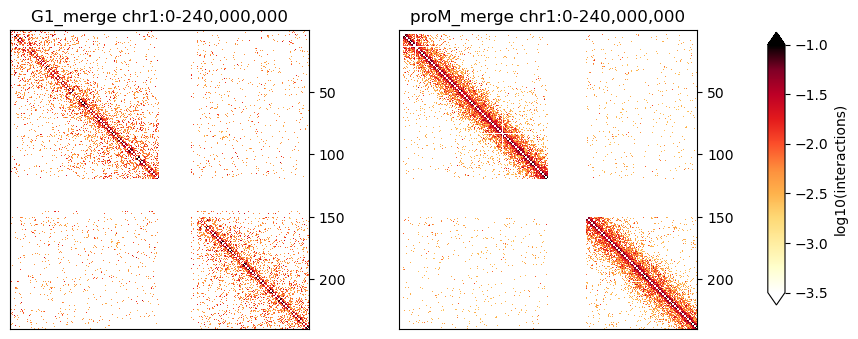

In [87]:
plottingregion = 'chr1:0-240,000,000'
chromarm = ('chr1', 0,240000000)

opts = dict(
    vmin=-3.5, #change scale range here; if log (-3.5, -0.5)
    vmax=-1,
    cmap='fall'
)

fig = plt.figure(figsize=((4.5 * 2) + 1, 5))

gs00 = GridSpec(nrows = 1, ncols = 2, width_ratios = [20*2] + [1], wspace=0.2)

gs_cb = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1], wspace = 0.1, subplot_spec = gs00[1])

#how many heatmaps
gs0 = GridSpecFromSubplotSpec(nrows=1, ncols=2, wspace = 0.3, subplot_spec = gs00[0])

for i, cond in enumerate(conditions):
    gs1 = GridSpecFromSubplotSpec(nrows = 2, ncols = 1, height_ratios=[6, 1], wspace=0.1, 
                                  hspace = 0.05, subplot_spec = gs0[i])

    c = clrs[cond]
    cis = c.matrix(balance = True).fetch(plottingregion)
    
    n,j = np.indices(cis.shape)
    n = n.flatten()
    j = j.flatten()
    # fill NaNs inside of the desired selection:
    nan_band_selector = (np.abs(n-j) < 2) #fills 2 bins on diagonal with nan
    cis[n[nan_band_selector],j[nan_band_selector]] = np.nan
    
    cisbins = c.bins().fetch(plottingregion)

    mids = cisbins['end'] - binsize/2
    mids = mids.reset_index(drop=True)
    
    #plot heatmap
    ax = plt.subplot(gs1[0, 0])
    img = ax.matshow( #can change this to plt.imshow instead probably?
        np.log10(cis), 
#        cis,
        extent=[
            mids[0]/1000000, 
            mids.iloc[-1]/1000000, 
            mids.iloc[-1]/1000000, 
            mids[0]/1000000], 
        **opts)
    ax.xaxis.set_visible(False)
    ax.yaxis.tick_right()    
    ax.set_aspect('equal')
    plt.title(samplePlotNames[cond] + ' ' + plottingregion)
    
    # barplot of eigenvalues

#    ax1 = plt.subplot(gs1[1, 0])
#    plt.ylim(-2, 2) 
#    plt.xlim(chromarm[1]/1000000, chromarm[2]/1000000)
#    img2 = ax1.bar(
#        x = list((eigs['G1_merge'][eigs['G1_merge'].chrom == chromarm[0]]['start'] + binsize/2)/1000000), 
#        height = list(eigs['G1_merge'][eigs['G1_merge'].chrom == chromarm[0]]['E1']),
#        width = 0.25,
#        color=eigs['G1_merge'].E1[eigs['G1_merge'].chrom == chromarm[0]].apply(lambda x: 'r' if x>0 else 'b')
#                  )
#    plt.ylabel('G1 Eig 1')
#    plt.xlabel('Mb' )
#    ax1.xaxis.set_ticks(np.arange(20, 110, 10)) #This specifically sets ticks to this range, to match y axis
#    fig.add_subplot(ax1)
    
# color bar in it's own axis, and own gridspace
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(img, cax = colorAx, extend = 'both')
    cb.set_label('log10(interactions)')

#plt.suptitle(f'Chr14 Heatmaps and Eigen1 200kb Bins')
#plt.savefig("{}/figures/ASG1Sort_R1R2Combined_FullChr14Heatmaps_250kbBins_MinusDiag_WithEigen1_Barplot_columns.png".format(outDataDir), dpi = 300, bbox_inches = 'tight')

In [76]:
##heatmap ploting -2 (corrected frequency by weight)

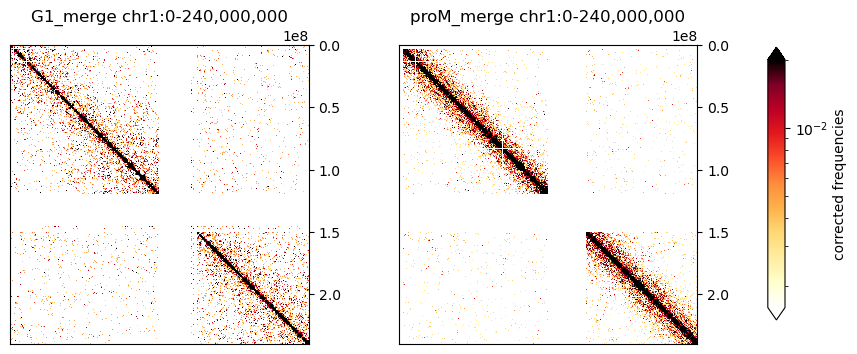

In [88]:
start = 0
end = 240_000_000
region = ('chr1', start, end)
norm = LogNorm(vmax=0.02) #set the scale range

fig = plt.figure(figsize=((4.5 * 2) + 1, 5))

gs00 = GridSpec(nrows = 1, ncols = 2, width_ratios = [20*2] + [1], wspace=0.2)

gs_cb = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1], wspace = 0.1, subplot_spec = gs00[1])

#how many heatmaps
gs0 = GridSpecFromSubplotSpec(nrows=1, ncols=2, wspace = 0.3, subplot_spec = gs00[0])

for i, cond in enumerate(conditions):
    gs1 = GridSpecFromSubplotSpec(nrows = 2, ncols = 1, height_ratios=[6, 1], wspace=0.1, 
                                  hspace = 0.05, subplot_spec = gs0[i])
        
    #plot heatmap
    ax = plt.subplot(gs1[0, 0])
    im = ax.matshow(
    clrs[cond].matrix().fetch(region),
    norm=norm,
    cmap='fall',
    extent=(start, end, end, start)
    );
    ax.xaxis.set_visible(False)
    ax.yaxis.tick_right()    
    ax.set_aspect('equal')
    plt.title(samplePlotNames[cond] + ' ' + plottingregion)
    
    # barplot of eigenvalues

#    ax1 = plt.subplot(gs1[1, 0])
#    plt.ylim(-2, 2) 
#    plt.xlim(chromarm[1]/1000000, chromarm[2]/1000000)
#    img2 = ax1.bar(
#        x = list((eigs['G1_merge'][eigs['G1_merge'].chrom == chromarm[0]]['start'] + binsize/2)/1000000), 
#        height = list(eigs['G1_merge'][eigs['G1_merge'].chrom == chromarm[0]]['E1']),
#        width = 0.25,
#        color=eigs['G1_merge'].E1[eigs['G1_merge'].chrom == chromarm[0]].apply(lambda x: 'r' if x>0 else 'b')
#                  )
#    plt.ylabel('G1 Eig 1')
#    plt.xlabel('Mb' )
#    ax1.xaxis.set_ticks(np.arange(20, 110, 10)) #This specifically sets ticks to this range, to match y axis
#    fig.add_subplot(ax1)
    
# color bar in it's own axis, and own gridspace
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(im, cax = colorAx, extend = 'both')
    cb.set_label('corrected frequencies')
    
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap of beachmark {plottingregion}.pdf", 
            format="pdf", bbox_inches="tight")


In [51]:
#set path and condition of single-cell HiC
pathcool = "/home/xiangru.huo-umw/scHiC/benchmark/scHiC_1203_2022/1+2_sc_results/coolers_library"
conditions = [
    'cell1',
    'cell2',  
    'cell3',
    'cell4']

binsize =500000

cooler_paths = { 
    'cell1' : '{}/scHiC_cell73.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool),
    'cell2' : '{}/scHiC_cell62.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool),
    'cell3' : '{}/scHiC_cell81.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool),
    'cell4' : '{}/scHiC_cell86.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool)
}

long_names = { 
    'cell1' : 'cell1_proM',
    'cell2' : 'cell2_proM',
    'cell3' : 'cell3_G1',
    'cell4' : 'cell4_G1'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'cell1' : 'cell1_proM',
    'cell2' : 'cell2_proM',
    'cell3' : 'cell3_G1',
    'cell4' : 'cell4_G1'
}

In [52]:
clrs['cell1'].info

{'bin-size': 500000,
 'bin-type': 'fixed',
 'creation-date': '2023-01-10T18:41:14.876628',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 6189,
 'nchroms': 25,
 'nnz': 78390,
 'storage-mode': 'symmetric-upper',
 'sum': 674377}

In [53]:
clrs['cell2'].info

{'bin-size': 500000,
 'bin-type': 'fixed',
 'creation-date': '2023-01-10T18:39:40.495786',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 6189,
 'nchroms': 25,
 'nnz': 90472,
 'storage-mode': 'symmetric-upper',
 'sum': 830223}

In [54]:
clrs['cell3'].info

{'bin-size': 500000,
 'bin-type': 'fixed',
 'creation-date': '2023-01-10T18:40:34.136376',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 6189,
 'nchroms': 25,
 'nnz': 61262,
 'storage-mode': 'symmetric-upper',
 'sum': 703962}

In [55]:
clrs['cell4'].info

{'bin-size': 500000,
 'bin-type': 'fixed',
 'creation-date': '2023-01-10T18:42:20.099245',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 6189,
 'nchroms': 25,
 'nnz': 101652,
 'storage-mode': 'symmetric-upper',
 'sum': 885393}

In [56]:
#set bin size
bins = cooler.binnify(hg38_chromsizes, binsize)
#check the binsize again
clrs['cell1'].binsize

500000

In [ ]:
#Plot heatmap for dropletHiC

In [8]:
#set path and condition
pathcool = "/home/xiangru.huo-umw/scHiC/mapping/dropletHiC_proM_G1_1800M/coolers_library"
conditions = [
    'G1_merge_10X',  
    'proM_merge_10X']

binsize = 250000

cooler_paths = { 
    'G1_merge_10X' : '{}/Asyn_10X_20251017.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool),
    'proM_merge_10X' : '{}/ProM_10X_20251017.hg38.mapq_30.1000.mcool::resolutions/500000'.format(pathcool)
}

long_names = {    
    'G1_merge_10X' : 'G1_merge_dropletHiC', 
    'proM_merge_10X' : 'proM_merge_dropletHiC' 
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

Saved to: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_fall_chr1_0-240000000.pdf


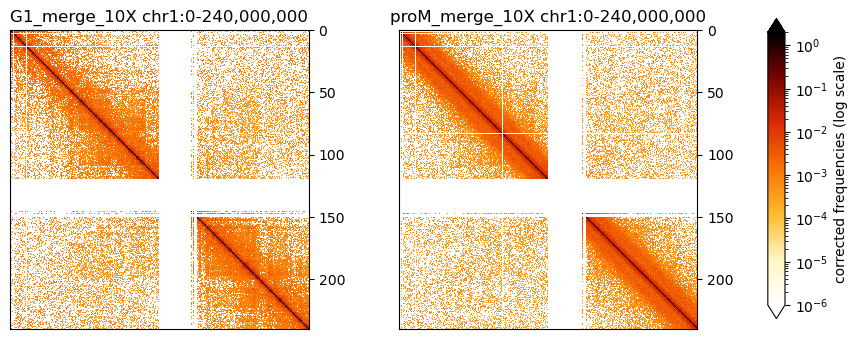

In [35]:
from matplotlib.colors import LinearSegmentedColormap

# === Define the correct "fall-like" colormap (white → yellow → orange → red → black) ===
fall_colors = ["#ffffff", "#fff5c3", "#fdbb2d", "#f97306", "#d92b04", "#7a0403", "#000000"]
fall_cmap = LinearSegmentedColormap.from_list("fall_corrected", fall_colors, N=256)
fall_cmap_r = fall_cmap.reversed()  # darker = higher frequencies

# === Region and settings ===
start = 0
end = 240_000_000
region = ('chr1', start, end)
plottingregion = f"chr1:{start:,}-{end:,}"

# Log scale normalization
norm = LogNorm(vmin=1e-6, vmax=2e+0)  # tweak vmax if needed for your data range

# === Figure setup ===
fig = plt.figure(figsize=((4.5 * 2) + 1, 5))
gs00 = GridSpec(nrows=1, ncols=2, width_ratios=[20*2, 1], wspace=0.2)
gs_cb = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1], wspace=0.1, subplot_spec=gs00[1])
gs0 = GridSpecFromSubplotSpec(nrows=1, ncols=2, wspace=0.3, subplot_spec=gs00[0])

im = None

for i, cond in enumerate(conditions):
    gs1 = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1],
                                  wspace=0.1, hspace=0.05, subplot_spec=gs0[i])
    ax = plt.subplot(gs1[0, 0])

    # Fetch and clean matrix
    m = np.asarray(clrs[cond].matrix().fetch(region), dtype=float)
    m[~np.isfinite(m)] = np.nan
    m[m <= 0] = np.nan

    im = ax.imshow(
        m,
        origin="upper",
        cmap=fall_cmap,        # use the custom palette
        norm=norm,
        extent=(start/1e6, end/1e6, end/1e6, start/1e6),
        interpolation="nearest"
    )

    ax.xaxis.set_visible(False)
    ax.yaxis.tick_right()
    ax.set_aspect('equal')
    plt.title(f"{cond} {plottingregion}")

# === Shared colorbar ===
colorAx = plt.subplot(gs_cb[0, 0])
cb = plt.colorbar(im, cax=colorAx, extend='both')
cb.set_label('corrected frequencies (log scale)')

# optional: force scientific tick labels like 10^-2, 10^-4
from matplotlib.ticker import LogFormatterMathtext
cb.formatter = LogFormatterMathtext()
cb.update_ticks()

# === Save ===
outf = f"/home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_fall_{plottingregion.replace(':','_').replace(',','')}.pdf"
plt.savefig(outf, format="pdf", bbox_inches="tight")
print("Saved to:", outf)

# five stages heatmap (bulk)

In [38]:
#set path and condition of five stages
pathcool = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk"
conditions = [
    'ES',
    'DE',  
    'HB',
    'iHep',
    'mHep']

binsize =1000000

cooler_paths = { 
    'ES' : '{}/ESC-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'DE' : '{}/DE-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'HB' : '{}/HB-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'iHep' : '{}/iHEP-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool),
    'mHep' : '{}/mHEP-DdeI-DpnII-R1R2.hg38.mapq_30.1000.mcool::resolutions/1000000'.format(pathcool)

}

long_names = { 
    'ES' : 'ES_rep12',
    'DE' : 'DE_rep12',  
    'HB' : 'HB_rep12',
    'iHep' : 'iHep_rep12',
    'mHep' : 'mHep_rep12'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'ES' : 'ES',
    'DE' : 'DE',  
    'HB' : 'HB',
    'iHep' : 'iHep',
    'mHep' : 'mHep'
}

In [39]:
clrs['ES'].info

{'bin-size': 1000000,
 'bin-type': 'fixed',
 'creation-date': '2023-07-19T11:05:07.242499',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 3103,
 'nchroms': 25,
 'nnz': 4266832,
 'storage-mode': 'symmetric-upper',
 'sum': 2125650482}

In [40]:
clrs['DE'].info

{'bin-size': 1000000,
 'bin-type': 'fixed',
 'creation-date': '2023-07-19T11:02:52.941102',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 3103,
 'nchroms': 25,
 'nnz': 4269145,
 'storage-mode': 'symmetric-upper',
 'sum': 2165357845}

In [41]:
clrs['HB'].info

{'bin-size': 1000000,
 'bin-type': 'fixed',
 'creation-date': '2023-07-19T10:41:26.506178',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 3103,
 'nchroms': 25,
 'nnz': 4233082,
 'storage-mode': 'symmetric-upper',
 'sum': 2099163811}

In [42]:
clrs['iHep'].info

{'bin-size': 1000000,
 'bin-type': 'fixed',
 'creation-date': '2023-07-19T10:35:56.752597',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 3103,
 'nchroms': 25,
 'nnz': 4214297,
 'storage-mode': 'symmetric-upper',
 'sum': 1681998365}

In [43]:
clrs['mHep'].info

{'bin-size': 1000000,
 'bin-type': 'fixed',
 'creation-date': '2023-07-19T10:26:35.177402',
 'format': 'HDF5::Cooler',
 'format-url': 'https://github.com/mirnylab/cooler',
 'format-version': 3,
 'generated-by': 'cooler-0.8.5',
 'genome-assembly': 'unknown',
 'metadata': {},
 'nbins': 3103,
 'nchroms': 25,
 'nnz': 4208945,
 'storage-mode': 'symmetric-upper',
 'sum': 1412924753}

In [10]:
#set bin size
bins = cooler.binnify(hg38_chromsizes, binsize)
#check the binsize again
clrs['mHep'].binsize

1000000

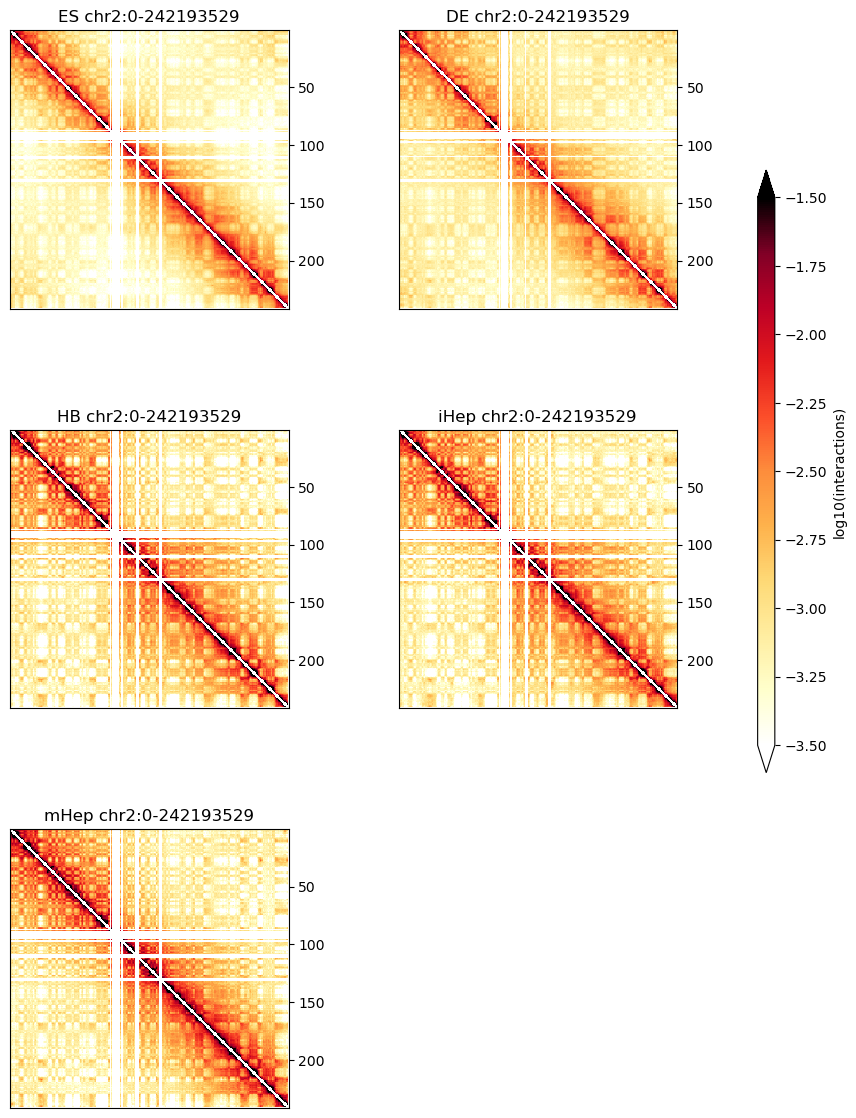

In [44]:
#plottingregion = 'chr4:0-100,000,000'
#chromarm = ('chr4', 0,100000000)

plottingregion = 'chr2:0-242193529'
chromarm = ('chr2',0,242193529)

opts = dict(
    vmin=-3.5, #change scale range here; if log (-3.5, -0.5)
    vmax=-1.5,
    cmap='fall'
)

fig = plt.figure(figsize=((4.5 * 2) + 1, 50))

gs00 = GridSpec(nrows = 3, ncols = 2, width_ratios = [20*2] + [1], wspace=0.2)

gs_cb = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1], wspace = 0.1, subplot_spec = gs00[1])

#how many heatmaps
gs0 = GridSpecFromSubplotSpec(nrows=3, ncols=2, wspace = 0.3, subplot_spec = gs00[0])

for i, cond in enumerate(conditions):
    gs1 = GridSpecFromSubplotSpec(nrows = 2, ncols = 1, height_ratios=[6, 1], wspace=0.1, 
                                  hspace = 0.05, subplot_spec = gs0[i])

    c = clrs[cond]
    cis = c.matrix(balance = True).fetch(plottingregion)
    
    n,j = np.indices(cis.shape)
    n = n.flatten()
    j = j.flatten()
    # fill NaNs inside of the desired selection:
    nan_band_selector = (np.abs(n-j) < 2) #fills 2 bins on diagonal with nan
    cis[n[nan_band_selector],j[nan_band_selector]] = np.nan
    
    cisbins = c.bins().fetch(plottingregion)

    mids = cisbins['end'] - binsize/2
    mids = mids.reset_index(drop=True)
    
    #plot heatmap
    ax = plt.subplot(gs1[0, 0])
    img = ax.matshow( #can change this to plt.imshow instead probably?
        np.log10(cis), 
#        cis,
        extent=[
            mids[0]/1000000, 
            mids.iloc[-1]/1000000, 
            mids.iloc[-1]/1000000, 
            mids[0]/1000000], 
        **opts)
    ax.xaxis.set_visible(False)
    ax.yaxis.tick_right()    
    ax.set_aspect('equal')
    plt.title(samplePlotNames[cond] + ' ' + plottingregion)
        
# color bar in it's own axis, and own gridspace
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(img, cax = colorAx, extend = 'both')
    cb.set_label('log10(interactions)')


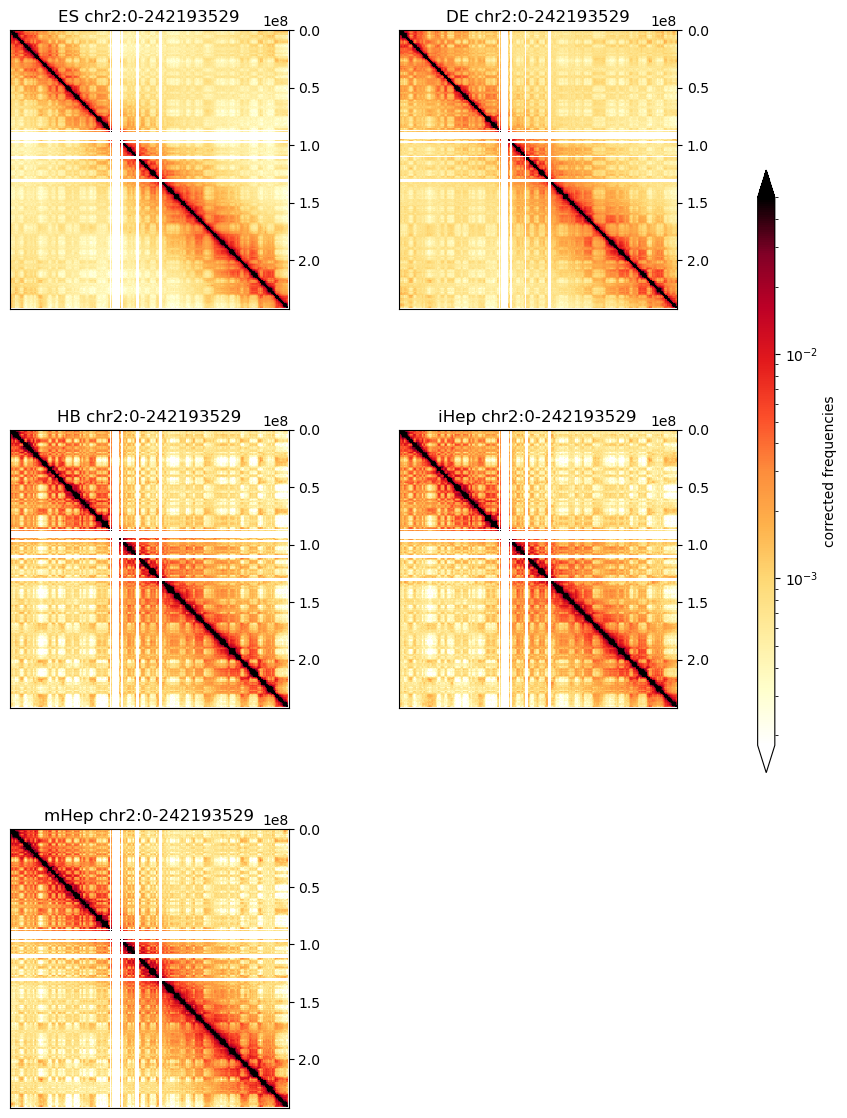

In [45]:
start = 0
#end = 100_000_000
end = 242193529
#region = ('chr4', start, end)
region = ('chr2', start, end)
norm = LogNorm(vmax=0.05) #set the scale range

fig = plt.figure(figsize=((4.5 * 2) + 1, 50))

gs00 = GridSpec(nrows = 3, ncols = 2, width_ratios = [20*2] + [1], wspace=0.2)

gs_cb = GridSpecFromSubplotSpec(nrows=2, ncols=1, height_ratios=[6, 1], wspace = 0.1, subplot_spec = gs00[1])

#how many heatmaps
gs0 = GridSpecFromSubplotSpec(nrows=3, ncols=2, wspace = 0.3, subplot_spec = gs00[0])

for i, cond in enumerate(conditions):
    gs1 = GridSpecFromSubplotSpec(nrows = 2, ncols = 1, height_ratios=[6, 1], wspace=0.1, 
                                  hspace = 0.05, subplot_spec = gs0[i])
        
    #plot heatmap
    ax = plt.subplot(gs1[0, 0])
    im = ax.matshow(
    clrs[cond].matrix().fetch(region),
    norm=norm,
    cmap='fall',
    extent=(start, end, end, start)
    );
    ax.xaxis.set_visible(False)
    ax.yaxis.tick_right()    
    ax.set_aspect('equal')
    plt.title(samplePlotNames[cond] + ' ' + plottingregion)
        
# color bar in it's own axis, and own gridspace
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(im, cax = colorAx, extend = 'both')
    cb.set_label('corrected frequencies')
    
plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap of 5stages {plottingregion}.pdf", 
            format="pdf", bbox_inches="tight")


# plot chr2 and chr11 two chromosomes interaction heatmap

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import EngFormatter
import numpy as np

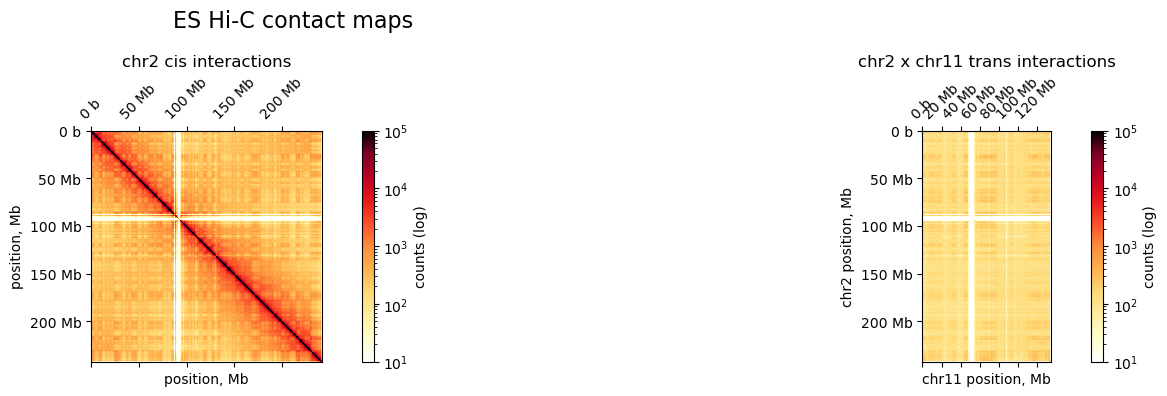

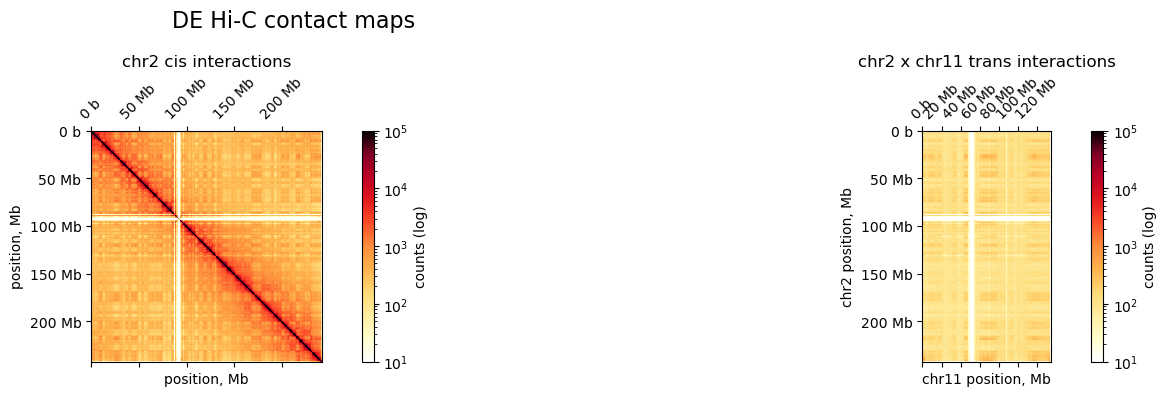

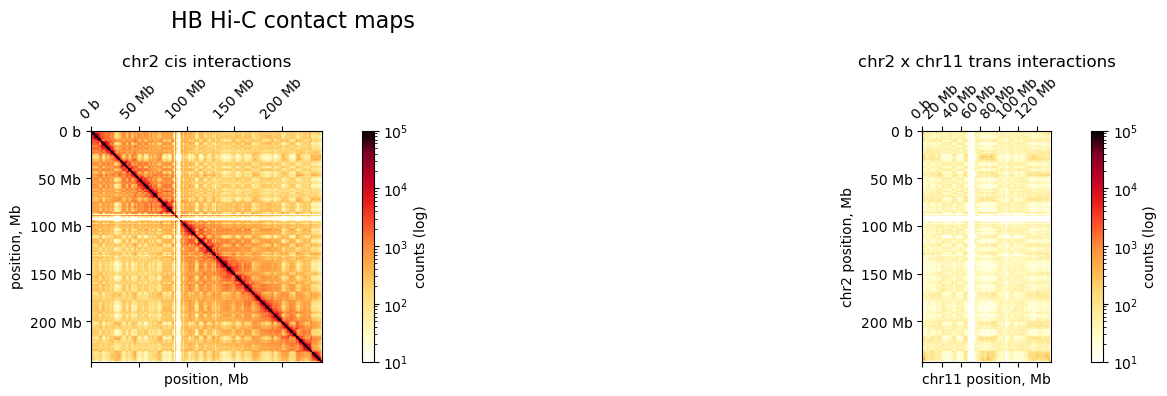

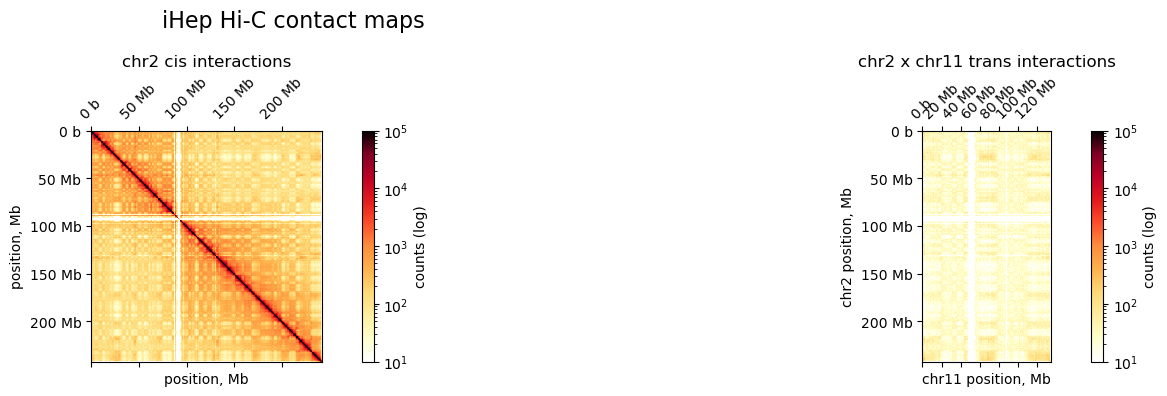

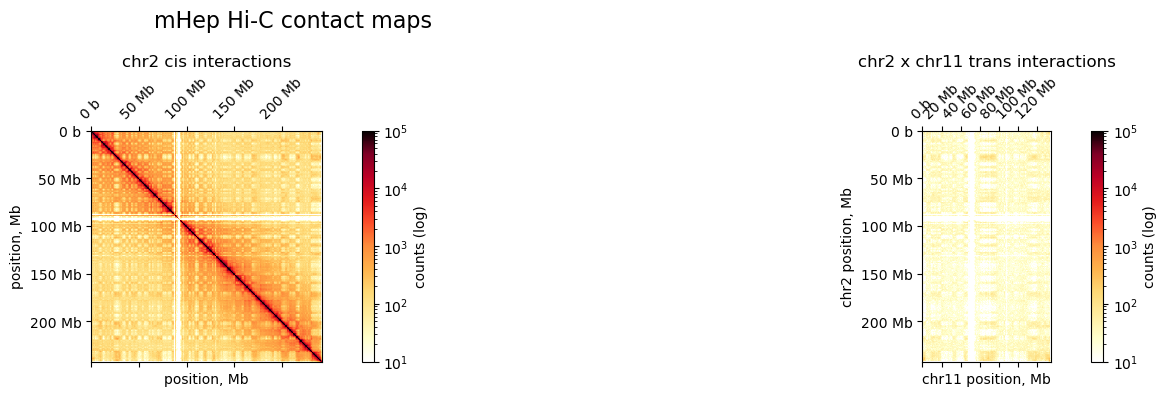

In [46]:
# Define tick formatter for bp to Mb
bp_formatter = EngFormatter('b')
norm = LogNorm(vmin=10, vmax=100_000)  # Adjust as needed

chrom2 = 'chr2'
chrom11 = 'chr11'

for cond in conditions:
    clr = clrs[cond]
    chrom2_len = clr.chromsizes[chrom2]
    chrom11_len = clr.chromsizes[chrom11]

    # Whole-genome tick positions (start of each chromosome)
    chromstarts = np.cumsum([0] + [clr.chromsizes[chrom] for chrom in clr.chromnames[:-1]])

    fig, axs = plt.subplots(figsize=(18, 4), ncols=2)
    fig.suptitle(f'{samplePlotNames[cond]} Hi-C contact maps', fontsize=16)

    # Panel 2: chr2 cis interaction
    ax = axs[0]
    im2 = ax.matshow(
        clr.matrix(balance=False).fetch(chrom2),
        norm=norm,
        extent=(0, chrom2_len, chrom2_len, 0),
        cmap='fall'
    )
    plt.colorbar(im2, ax=ax, fraction=0.046, pad=0.04, label='counts (log)')
    ax.set_title(f'{chrom2} cis interactions')
    ax.set_ylabel('position, Mb')
    ax.set_xlabel('position, Mb')
    ax.set_aspect('equal')
    ax.xaxis.set_major_formatter(bp_formatter)
    ax.yaxis.set_major_formatter(bp_formatter)
    ax.tick_params(axis='x', rotation=45)

    # Panel 3: chr2 x chr11 trans interaction
    ax = axs[1]
    im3 = ax.matshow(
        clr.matrix(balance=False).fetch(chrom2, chrom11),
        norm=norm,
        extent=(0, chrom11_len, chrom2_len, 0),
        cmap='fall'
    )
    plt.colorbar(im3, ax=ax, fraction=0.046, pad=0.04, label='counts (log)')
    ax.set_title(f'{chrom2} x {chrom11} trans interactions')
    ax.set_xlabel(f'{chrom11} position, Mb')
    ax.set_ylabel(f'{chrom2} position, Mb')
    ax.set_aspect('equal')
    ax.xaxis.set_major_formatter(bp_formatter)
    ax.yaxis.set_major_formatter(bp_formatter)
    ax.tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_ES_chr2_chr11.pdf


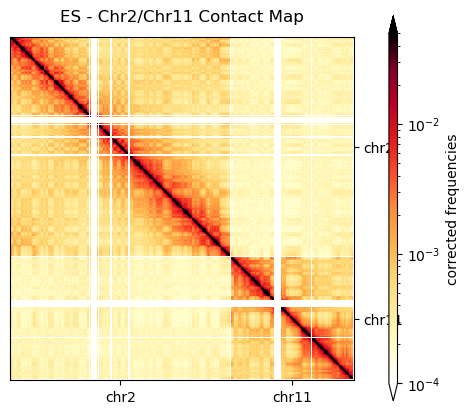

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_DE_chr2_chr11.pdf


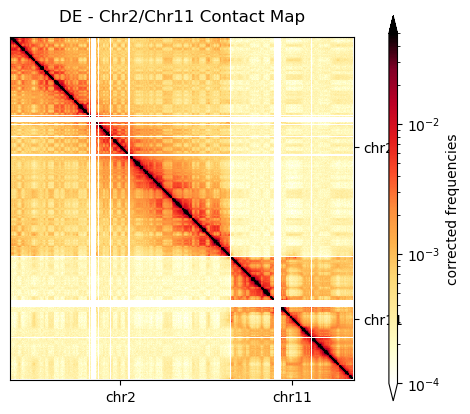

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_HB_chr2_chr11.pdf


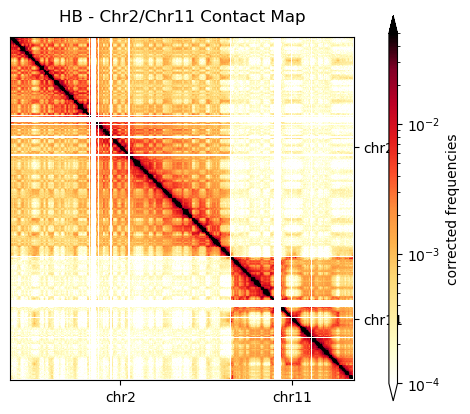

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_iHep_chr2_chr11.pdf


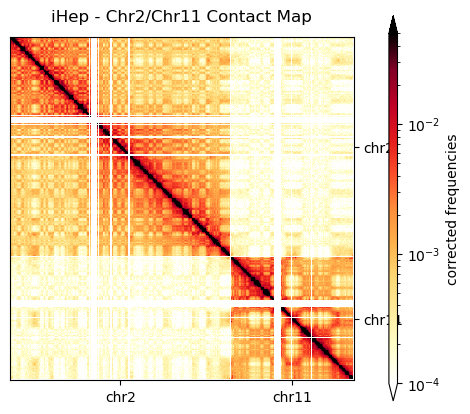

Saved: /home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap_mHep_chr2_chr11.pdf


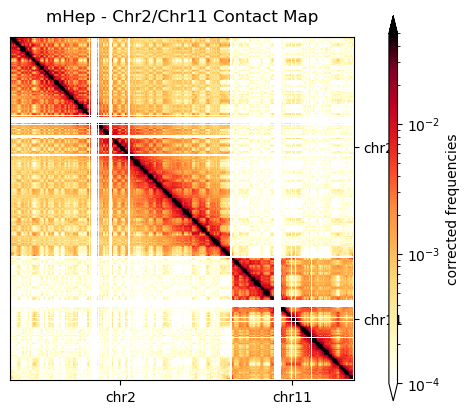

In [47]:
#layout chr2 and chr11 as square
start = 0
end = 242_193_529
region = ('chr2', start, end)
norm = LogNorm(vmin=1e-4, vmax=0.05)  # You can adjust vmin as needed
save_dir = "/home/xiangru.huo-umw/scHiC/scripts/plot"

chrom2 = 'chr2'
chrom11 = 'chr11'

for cond in conditions:
    clr = clrs[cond]
    
    # Fetch 4 blocks
    mat22 = clr.matrix(balance=True).fetch(chrom2, chrom2)
    mat21 = clr.matrix(balance=True).fetch(chrom2, chrom11)
    mat12 = clr.matrix(balance=True).fetch(chrom11, chrom2)
    mat11 = clr.matrix(balance=True).fetch(chrom11, chrom11)

    # Combine into 2x2 block
    top = np.hstack([mat22, mat21])
    bottom = np.hstack([mat12, mat11])
    full_matrix = np.vstack([top, bottom])

    # Sizes for extent in bp
    len2 = clr.chromsizes[chrom2]
    len11 = clr.chromsizes[chrom11]
    extent = [0, len2 + len11, len2 + len11, 0]

    # Set up layout
    fig = plt.figure(figsize=((4.5 * 1) + 0.5, 5))
    gs00 = GridSpec(nrows=1, ncols=2, width_ratios=[20*2, 1], wspace=0.2)
    gs_main = GridSpecFromSubplotSpec(nrows=1, ncols=1, subplot_spec=gs00[0])
    gs_cb = GridSpecFromSubplotSpec(nrows=1, ncols=1, subplot_spec=gs00[1])

    # Plot heatmap
    ax = plt.subplot(gs_main[0, 0])
    im = ax.matshow(
        full_matrix,
        norm=norm,
        cmap='fall',
        extent=extent
    )
    ax.set_xticks([len2/2, len2 + len11/2])
    ax.set_xticklabels([chrom2, chrom11])
    ax.set_yticks([len2/2, len2 + len11/2])
    ax.set_yticklabels([chrom2, chrom11])
    ax.xaxis.tick_bottom()
    ax.yaxis.tick_right()
    ax.set_title(f'{samplePlotNames[cond]} - Chr2/Chr11 Contact Map', y=1.02)
    ax.set_aspect('equal')

    # Colorbar
    colorAx = plt.subplot(gs_cb[0, 0])
    cb = plt.colorbar(im, cax=colorAx, extend='both')
    cb.set_label('corrected frequencies')
    
    # Save as PDF (one file per condition)
    save_path = os.path.join(save_dir, f"Heatmap_{cond}_chr2_chr11.pdf")
    plt.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Saved: {save_path}")

    plt.show()

# plot heatmap of 10 DNA FISH loci 

In [33]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import EngFormatter
import matplotlib.patches as patches

In [89]:
#set path and condition of five stages
pathcool = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mcool_bulk"
conditions = ['ES', 'DE', 'HB', 'iHep', 'mHep']
binsize = 25_000  # Set uniform resolution for all

# Matching prefixes for the file names
prefixes = {
    'ES': 'ESC',
    'DE': 'DE',
    'HB': 'HB',
    'iHep': 'iHEP',
    'mHep': 'mHEP'
}

# Construct the cooler paths
cooler_paths = {
    cond: f"{pathcool}/{prefixes[cond]}-FA-DSG-DdeI-DpnII-R2L1-4__hg38.hg38.mapq_30.1000.mcool::resolutions/{binsize}"
    for cond in conditions
}

long_names = { 
    'ES' : 'ES_rep12',
    'DE' : 'DE_rep12',  
    'HB' : 'HB_rep12',
    'iHep' : 'iHep_rep12',
    'mHep' : 'mHep_rep12'
}

clrs = {
    cond: cooler.Cooler(cooler_paths[cond]) for cond in conditions
}

samplePlotNames = {
    'ES' : 'ES',
    'DE' : 'DE',  
    'HB' : 'HB',
    'iHep' : 'iHep',
    'mHep' : 'mHep'
}

In [90]:
# Define box regions
box_regions = [
    ('chr11', 41_000_000, 41_500_000),
    ('chr11', 88_200_000, 88_400_000),
    ('chr11', 11_000_000, 12_000_000),
    ('chr11', 107_000_000, 109_000_000),
    ('chr11', 119_000_000, 120_000_000),
    ('chr2', 79_325_001, 83_775_000),
    ('chr2', 2_000_000, 3_800_000),
    ('chr2', 100_400_000, 102_000_000),
    ('chr2', 153_800_000, 154_500_000),
    ('chr2', 32_000_000, 32_500_000)
]

/tmp/ipykernel_935024/2041103778.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.87, 1])


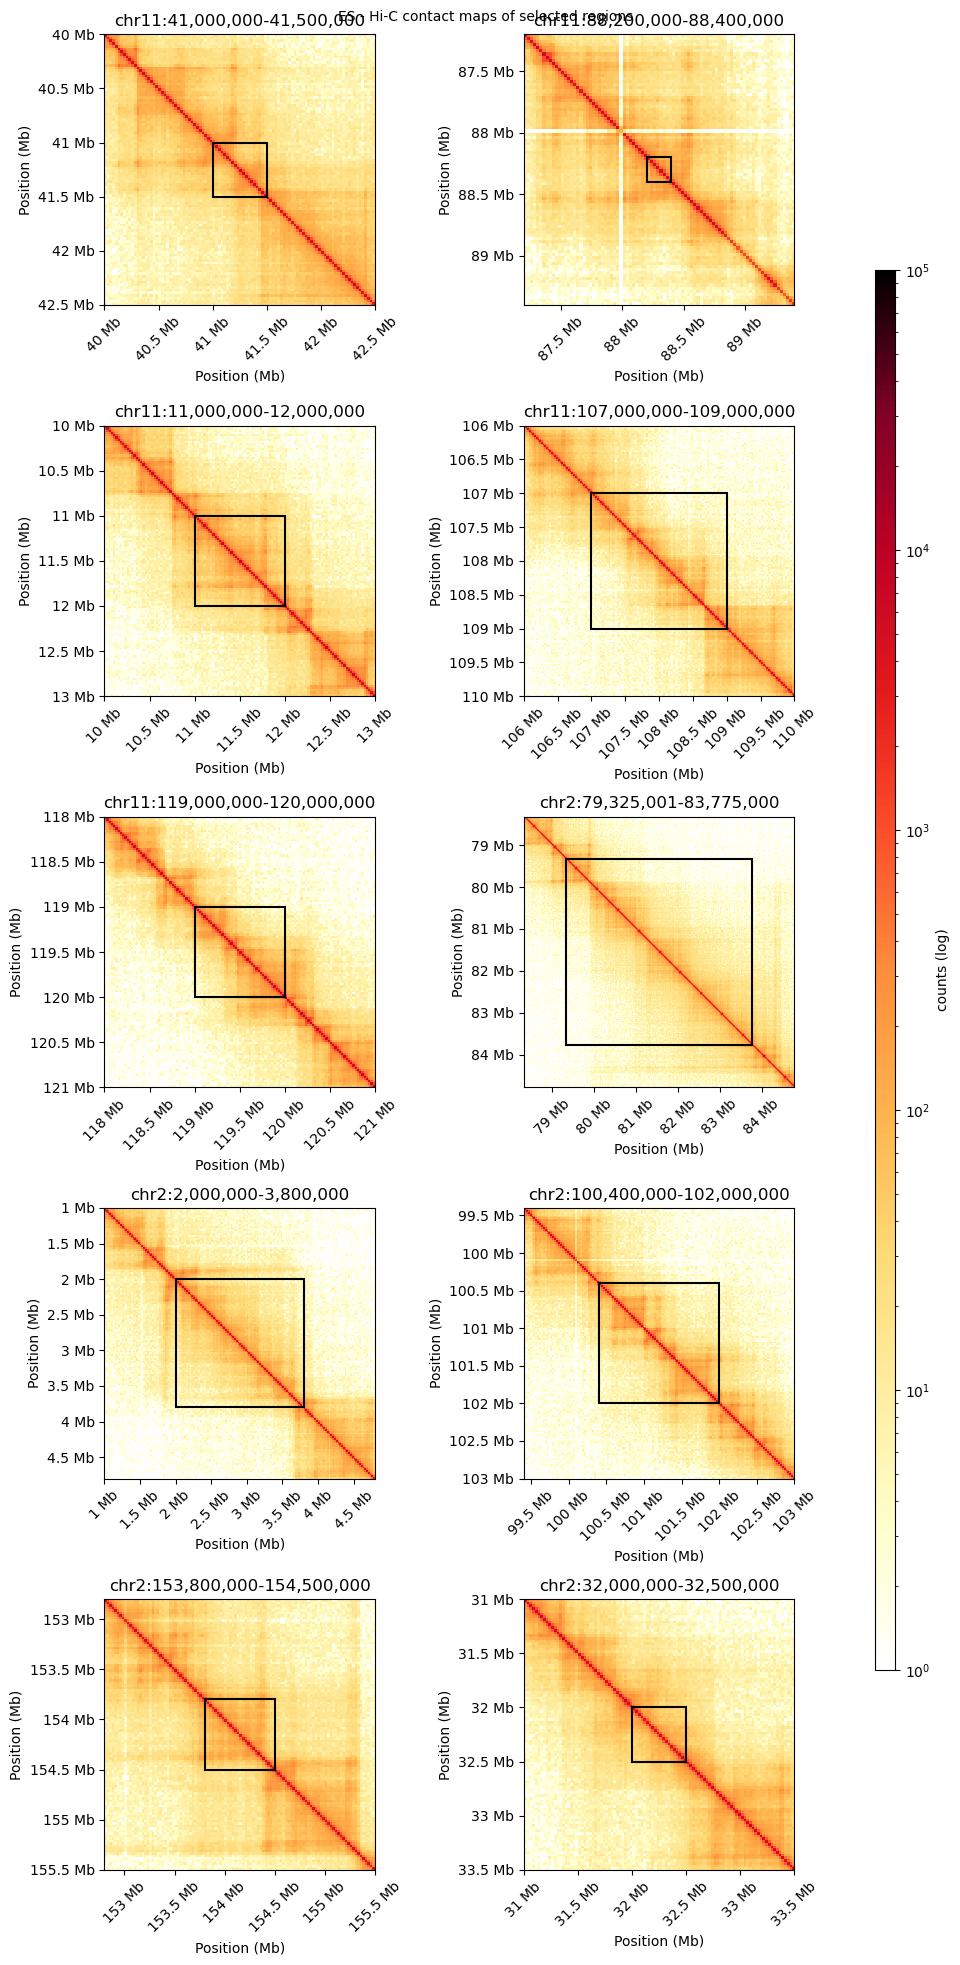

In [92]:
#plot the heatmap of these regions
# Plot settings
cond = 'ES'
clr = clrs[cond]
norm = LogNorm(vmin=1, vmax=100_000)
bp_formatter = EngFormatter('b')

# Set up figure: 5 rows × 2 columns
fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(10, 20))
axs = axs.flatten()

for i, (chrom, box_start, box_end) in enumerate(box_regions):
    ax = axs[i]

    # Define region around box (±2Mb)
    start = box_start - 1_000_000
    end = box_end + 1_000_000
    region = (chrom, start, end)

    # Fetch matrix
    matrix = clr.matrix(balance=False).fetch(region)

    # Plot matrix
    im = ax.matshow(
        matrix,
        norm=norm,
        cmap='fall',
        extent=(start, end, end, start)
    )

    # Format plot
    ax.set_title(f"{chrom}:{box_start:,}-{box_end:,}")
    ax.set_xlabel("Position (Mb)")
    ax.set_ylabel("Position (Mb)")
    ax.xaxis.set_major_formatter(bp_formatter)
    ax.yaxis.set_major_formatter(bp_formatter)
    ax.xaxis.tick_bottom()
    ax.tick_params(axis='x', rotation=45)
    ax.set_aspect('equal')

    # Draw black rectangle (box)
    box = patches.Rectangle(
        (box_start, box_start),
        box_end - box_start,
        box_end - box_start,
        linewidth=1.5,
        edgecolor='black',
        facecolor='none'
    )
    ax.add_patch(box)

# Add shared colorbar
fig.subplots_adjust(right=0.87)
cbar_ax = fig.add_axes([0.89, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("counts (log)")

fig.suptitle(f"{samplePlotNames[cond]} - Hi-C contact maps of selected regions", fontsize=10)
plt.tight_layout(rect=[0, 0, 0.87, 1])

#plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot/Heatmap of loci for DNA FISH.pdf", 
#            format="pdf", bbox_inches="tight")

plt.show()